# Week 4B ? Frozen DINO/DINOv2 segmentation heads

This notebook trains the required linear and +ms heads on the Week 4 photutils pseudo-labels, runs the Week 3 DINO ViT-S/8 attention baseline on the identical test split, evaluates the listed ablations with class-wise IoU, and writes the comparison table, confusion matrix, hard-set gallery, predictions, and PDF report.

Run the pseudo-label notebook first. Use a Colab/Kaggle GPU (T4 recommended), and keep the same `data/splits.json`. Backbones remain frozen and in eval mode; only BatchNorm and the 1x1 convolution train.


In [1]:
%pip -q install matplotlib pandas pillow reportlab

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [2]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Week-4

Mounted at /content/drive
/content/drive/MyDrive/Week-4


In [3]:
from pathlib import Path
import sys, json, csv, random, shutil
import numpy as np
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd()
if not (ROOT / 'src' / 'week4_segmentation.py').exists():
    raise FileNotFoundError('Run this notebook with the working directory set to the Week-4 folder from the repository.')
sys.path.insert(0, str(ROOT / 'src'))
from week4_segmentation import (load_arrays, load_backbone, extract_linear224_cache, train_setting,
    evaluate_naive_attention, evaluate_multiscale_tta, make_hard_gallery, write_comparison)
from week4_report import build_report

SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ALLOW_CPU_DEBUG=False  # Set True only for a tiny debug run; never report it as the full experiment.
if DEVICE.type != 'cuda' and not ALLOW_CPU_DEBUG:
    raise RuntimeError('A CUDA GPU is required for the full Week 4 experiment. In Colab choose Runtime > Change runtime type > T4 GPU.')
DATA_DIR=ROOT/'data'; PRED_DIR=ROOT/'results'/'predictions'; METRIC_DIR=ROOT/'results'/'metrics'
PRED_DIR.mkdir(parents=True,exist_ok=True); METRIC_DIR.mkdir(parents=True,exist_ok=True)
images,masks,ids,parts=load_arrays(ROOT)
minimum_test=max(10,int(0.8*round(0.20*len(ids))))
if len(parts['test']) < minimum_test:
    raise RuntimeError(f'Only {len(parts["test"])} valid test images remain; expected at least {minimum_test}. '
                       'Rerun the pseudo-label notebook and inspect its QC before training.')
print('device:',DEVICE,'| N:',len(ids),'| split sizes:',{k:len(v) for k,v in parts.items()})


device: cuda | N: 3000 | split sizes: {'train': 2100, 'validation': 300, 'test': 600}


## 1. Cache the required 224px DINOv2 last-layer patch features

This disk-backed fp16 cache is about 0.6 GB for 3,000 cutouts. It avoids repeating the frozen ViT-S/14 forward pass for the primary linear experiment. Larger-input and DINO ViT-S/8 ablations are computed on the fly to avoid multi-gigabyte caches.


In [4]:
cache_path=PRED_DIR/'dinov2_s14_224_features_fp16.npy'
model=load_backbone('dinov2_s14',DEVICE)
feature_cache=extract_linear224_cache(images,model,cache_path,DEVICE,batch_size=32,image_ids=ids)
del model
if torch.cuda.is_available(): torch.cuda.empty_cache()
print('Feature cache:',feature_cache.shape,feature_cache.dtype)


Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 309MB/s]


Cached 224px patch features: 800/3000
Cached 224px patch features: 1600/3000
Cached 224px patch features: 2400/3000
Cached 224px patch features: 3000/3000
Feature cache: (3000, 384, 16, 16) float16


## 2. Train the linear and +ms heads

The primary linear setup uses last-layer ViT-S/14 features at 224px (16x16 tokens). The requested ablations are linear ViT-S/14 at 448px (32x32 tokens) and linear DINO ViT-S/8 at 224px (28x28 tokens). The +ms model concatenates the last four DINOv2 layers at 448px (1,536 channels, 32x32 grid). The base DINOv2 ViT-S/14 is used because Week 3 did not show cleaner attention with registers. Training uses weighted cross-entropy, AdamW at 1e-3, up to 20 epochs, and validation foreground mean IoU for checkpoint selection. Batch size is reduced for larger inputs to protect T4 memory.


In [5]:
EPOCHS=20
results=[]

# Primary linear setting; cached features are used for training/validation.
r224=train_setting('linear_dinov2_s14_224','dinov2_s14','last',224,ROOT,DEVICE,
                   epochs=EPOCHS,batch_size=32,feature_cache=feature_cache)
results.append(r224)

# Larger input and finer-patch ablations.
r448=train_setting('linear_dinov2_s14_448','dinov2_s14','last',448,ROOT,DEVICE,
                   epochs=EPOCHS,batch_size=16)
results.append(r448)

r_s8=train_setting('linear_dino_s8_224','dino_s8','last',224,ROOT,DEVICE,
                   epochs=EPOCHS,batch_size=16)
results.append(r_s8)

# Four-layer multiscale features; compute frozen features on the fly at 448px.
r_ms_train=train_setting('plus_ms_train_no_tta','dinov2_s14','multiscale',448,ROOT,DEVICE,
                         epochs=EPOCHS,batch_size=16)
print('Selected validation checkpoint for +ms: ',r_ms_train['best_epoch'])


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


epoch 01/20 | train CE 0.7895 | val foreground mean IoU 0.2989
epoch 02/20 | train CE 0.5243 | val foreground mean IoU 0.3865
epoch 03/20 | train CE 0.4684 | val foreground mean IoU 0.4091
epoch 04/20 | train CE 0.4476 | val foreground mean IoU 0.4200
epoch 05/20 | train CE 0.4364 | val foreground mean IoU 0.4194
epoch 06/20 | train CE 0.4287 | val foreground mean IoU 0.4297
epoch 07/20 | train CE 0.4239 | val foreground mean IoU 0.4284
epoch 08/20 | train CE 0.4183 | val foreground mean IoU 0.4375
epoch 09/20 | train CE 0.4160 | val foreground mean IoU 0.4388
epoch 10/20 | train CE 0.4125 | val foreground mean IoU 0.4428
epoch 11/20 | train CE 0.4114 | val foreground mean IoU 0.4394
epoch 12/20 | train CE 0.4088 | val foreground mean IoU 0.4382
epoch 13/20 | train CE 0.4080 | val foreground mean IoU 0.4471
epoch 14/20 | train CE 0.4062 | val foreground mean IoU 0.4334
epoch 15/20 | train CE 0.4050 | val foreground mean IoU 0.4471
epoch 16/20 | train CE 0.4048 | val foreground mean IoU

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


epoch 01/20 | train CE 0.6121 | val foreground mean IoU 0.4150
epoch 02/20 | train CE 0.4150 | val foreground mean IoU 0.4304
epoch 03/20 | train CE 0.3892 | val foreground mean IoU 0.4679
epoch 04/20 | train CE 0.3780 | val foreground mean IoU 0.4809
epoch 05/20 | train CE 0.3720 | val foreground mean IoU 0.4838
epoch 06/20 | train CE 0.3680 | val foreground mean IoU 0.5066
epoch 07/20 | train CE 0.3647 | val foreground mean IoU 0.4926
epoch 08/20 | train CE 0.3631 | val foreground mean IoU 0.4996
epoch 09/20 | train CE 0.3607 | val foreground mean IoU 0.4867
epoch 10/20 | train CE 0.3601 | val foreground mean IoU 0.4987
epoch 11/20 | train CE 0.3580 | val foreground mean IoU 0.5005
epoch 12/20 | train CE 0.3574 | val foreground mean IoU 0.4966
epoch 13/20 | train CE 0.3572 | val foreground mean IoU 0.4973
epoch 14/20 | train CE 0.3577 | val foreground mean IoU 0.4879
epoch 15/20 | train CE 0.3555 | val foreground mean IoU 0.5080
epoch 16/20 | train CE 0.3550 | val foreground mean IoU

100%|██████████| 82.7M/82.7M [00:00<00:00, 274MB/s]


epoch 01/20 | train CE 0.5859 | val foreground mean IoU 0.4505
epoch 02/20 | train CE 0.3719 | val foreground mean IoU 0.4820
epoch 03/20 | train CE 0.3466 | val foreground mean IoU 0.4969
epoch 04/20 | train CE 0.3368 | val foreground mean IoU 0.5027
epoch 05/20 | train CE 0.3314 | val foreground mean IoU 0.5015
epoch 06/20 | train CE 0.3286 | val foreground mean IoU 0.5142
epoch 07/20 | train CE 0.3259 | val foreground mean IoU 0.5193
epoch 08/20 | train CE 0.3248 | val foreground mean IoU 0.5191
epoch 09/20 | train CE 0.3234 | val foreground mean IoU 0.5159
epoch 10/20 | train CE 0.3223 | val foreground mean IoU 0.5195
epoch 11/20 | train CE 0.3212 | val foreground mean IoU 0.5167
epoch 12/20 | train CE 0.3217 | val foreground mean IoU 0.5264
epoch 13/20 | train CE 0.3207 | val foreground mean IoU 0.5153
epoch 14/20 | train CE 0.3203 | val foreground mean IoU 0.5203
epoch 15/20 | train CE 0.3202 | val foreground mean IoU 0.5179
epoch 16/20 | train CE 0.3194 | val foreground mean IoU

Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


epoch 01/20 | train CE 0.4847 | val foreground mean IoU 0.5173
epoch 02/20 | train CE 0.3436 | val foreground mean IoU 0.5216
epoch 03/20 | train CE 0.3271 | val foreground mean IoU 0.5368
epoch 04/20 | train CE 0.3213 | val foreground mean IoU 0.5412
epoch 05/20 | train CE 0.3170 | val foreground mean IoU 0.5143
epoch 06/20 | train CE 0.3158 | val foreground mean IoU 0.5164
epoch 07/20 | train CE 0.3143 | val foreground mean IoU 0.5376
epoch 08/20 | train CE 0.3103 | val foreground mean IoU 0.5553
epoch 09/20 | train CE 0.3108 | val foreground mean IoU 0.5522
epoch 10/20 | train CE 0.3096 | val foreground mean IoU 0.5513
epoch 11/20 | train CE 0.3083 | val foreground mean IoU 0.5437
epoch 12/20 | train CE 0.3074 | val foreground mean IoU 0.5421
epoch 13/20 | train CE 0.3073 | val foreground mean IoU 0.5438
epoch 14/20 | train CE 0.3076 | val foreground mean IoU 0.5533
epoch 15/20 | train CE 0.3054 | val foreground mean IoU 0.5379
epoch 16/20 | train CE 0.3057 | val foreground mean IoU

## 3. Test-time augmentation and Week 3 attention baseline

+ms test-time augmentation averages softmax predictions for 336, 448, and 560px inputs, each with and without a horizontal flip. The Week 3 baseline keeps the smallest per-head patch set containing 60% of CLS-to-patch attention mass. Its metrics are binary IoUs against all detected sources (classes 1+2) and against target class 1; it has no three-class mIoU. Per-head scores are averaged over the six DINO heads and held-out test cutouts.


In [6]:
ms_result,ms_predictions=evaluate_multiscale_tta(ROOT,PRED_DIR/'plus_ms_train_no_tta.pt',DEVICE,batch_size=4)
naive_result,naive_predictions=evaluate_naive_attention(ROOT,DEVICE,batch_size=16,fraction=0.60)
ms_result.update({'best_epoch':r_ms_train['best_epoch'],
                   'best_val_foreground_mean_iou':r_ms_train['best_val_foreground_mean_iou']})
results.append(ms_result)


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


+ms TTA evaluated 4/600
+ms TTA evaluated 8/600
+ms TTA evaluated 12/600
+ms TTA evaluated 16/600
+ms TTA evaluated 20/600
+ms TTA evaluated 24/600
+ms TTA evaluated 28/600
+ms TTA evaluated 32/600
+ms TTA evaluated 36/600
+ms TTA evaluated 40/600
+ms TTA evaluated 44/600
+ms TTA evaluated 48/600
+ms TTA evaluated 52/600
+ms TTA evaluated 56/600
+ms TTA evaluated 60/600
+ms TTA evaluated 64/600
+ms TTA evaluated 68/600
+ms TTA evaluated 72/600
+ms TTA evaluated 76/600
+ms TTA evaluated 80/600
+ms TTA evaluated 84/600
+ms TTA evaluated 88/600
+ms TTA evaluated 92/600
+ms TTA evaluated 96/600
+ms TTA evaluated 100/600
+ms TTA evaluated 104/600
+ms TTA evaluated 108/600
+ms TTA evaluated 112/600
+ms TTA evaluated 116/600
+ms TTA evaluated 120/600
+ms TTA evaluated 124/600
+ms TTA evaluated 128/600
+ms TTA evaluated 132/600
+ms TTA evaluated 136/600
+ms TTA evaluated 140/600
+ms TTA evaluated 144/600
+ms TTA evaluated 148/600
+ms TTA evaluated 152/600
+ms TTA evaluated 156/600
+ms TTA eval

Using cache found in /root/.cache/torch/hub/facebookresearch_dino_main


Naive attention evaluated 400/600 test cutouts
Naive attention evaluated 600/600 test cutouts


## 4. Final test comparison, class IoU, and confusion matrix

The test set is used only here for final metrics. For supervised settings mIoU is the mean of the dataset-level IoUs for background, target galaxy, and other sources; class-wise scores are saved in the JSON records. The attention baseline is reported separately because it cannot predict classes.


[{'setting': 'naive_attention_week3_dino_s8',
  'backbone': 'DINO ViT-S/8',
  'input_px': 224,
  'patch_grid': '28x28',
  'mIoU': None,
  'all_source_iou': 0.24480482492096323,
  'target_IoU': 0.05517552868936851},
 {'setting': 'linear_dinov2_s14_224',
  'backbone': 'dinov2_s14',
  'input_px': 224,
  'patch_grid': '16x16',
  'mIoU': 0.6123649806282876,
  'all_source_iou': None,
  'target_IoU': 0.5458073231395322},
 {'setting': 'linear_dinov2_s14_448',
  'backbone': 'dinov2_s14',
  'input_px': 448,
  'patch_grid': '32x32',
  'mIoU': 0.648611740639561,
  'all_source_iou': None,
  'target_IoU': 0.584508319100691},
 {'setting': 'linear_dino_s8_224',
  'backbone': 'dino_s8',
  'input_px': 224,
  'patch_grid': '28x28',
  'mIoU': 0.6655857562937103,
  'all_source_iou': None,
  'target_IoU': 0.5995123859130586},
 {'setting': 'plus_ms_tta',
  'backbone': 'DINOv2 ViT-S/14',
  'input_px': 448,
  'patch_grid': '32x32',
  'mIoU': 0.6830279520833322,
  'all_source_iou': None,
  'target_IoU': 0.59282

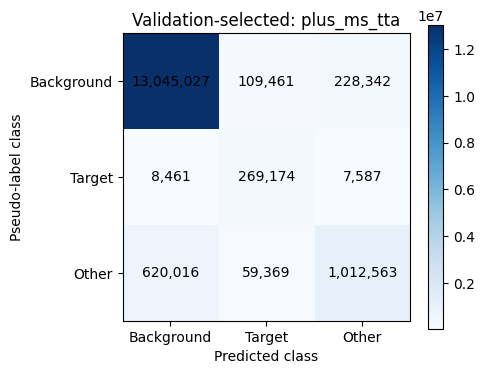

Confusion matrix uses the validation-selected setting: plus_ms_tta


In [7]:
# Save reproducible per-setting metrics under the requested metrics/ directory.
for result in results:
    source=PRED_DIR/f"{result['setting']}_metrics.json"
    if source.exists(): shutil.copy2(source,METRIC_DIR/f"{result['setting']}.json")
    else: (METRIC_DIR/f"{result['setting']}.json").write_text(json.dumps(result,indent=2),encoding='utf-8')
rows=write_comparison(ROOT,results,naive_result)
# Long-form per-class IoU table (one row per setting and segmentation class).
per_class=[]
for result in results:
    for class_name in ('background','target_galaxy','other_sources'):
        per_class.append({'setting':result['setting'],'class':class_name,'IoU':result.get(class_name)})
with (METRIC_DIR/'per_class_iou.csv').open('w',newline='',encoding='utf-8') as f:
    writer=csv.DictWriter(f,fieldnames=['setting','class','IoU']);writer.writeheader();writer.writerows(per_class)
display_rows=[{k:r.get(k) for k in ('setting','backbone','input_px','patch_grid','mIoU','all_source_iou','target_IoU')} for r in rows]
from IPython.display import display
display(display_rows)

# Confusion matrix for the highest-mIoU supervised configuration.
best=max(results,key=lambda r:float(r['best_val_foreground_mean_iou']))
if best['setting']=='plus_ms_tta': best_pred=ms_predictions
else: best_pred=np.load(PRED_DIR/f"{best['setting']}_test.npy")
_,_,_,parts=load_arrays(ROOT)
test_idx=parts['test']
conf=np.zeros((3,3),dtype=np.int64)
for pred,i in zip(best_pred,test_idx):
    truth=np.asarray(masks[int(i)]).ravel(); p=np.asarray(pred).ravel()
    conf += np.bincount(3*truth+p,minlength=9).reshape(3,3)
np.savetxt(METRIC_DIR/'best_confusion_matrix.csv',conf,delimiter=',',fmt='%d',
           header='pred_background,pred_target,pred_other',comments='')
fig,ax=plt.subplots(figsize=(5,4)); im=ax.imshow(conf,cmap='Blues')
ax.set_xticks(range(3),['Background','Target','Other']);ax.set_yticks(range(3),['Background','Target','Other'])
ax.set_xlabel('Predicted class');ax.set_ylabel('Pseudo-label class');ax.set_title(f"Validation-selected: {best['setting']}")
for y in range(3):
 for x in range(3): ax.text(x,y,f'{conf[y,x]:,}',ha='center',va='center',color='black')
fig.colorbar(im,ax=ax);fig.tight_layout();fig.savefig(METRIC_DIR/'best_confusion_matrix.png',dpi=180);plt.show()
print('Confusion matrix uses the validation-selected setting:',best['setting'])


## 5. Hard-set gallery

The default is an automatic proposal ranked by other-source pixel coverage. For the assignment?s hand-picked set, inspect the candidate gallery created by the pseudo-label notebook, then paste approximately 20 test IDs into `USER_HARD_SET_IDS` below and rerun this cell. The selected IDs are validated against the fixed test split. If left empty, the output is labelled as an automatic candidate set.


In [8]:
hard_file=ROOT/'results'/'pseudo_labels'/'hard_set_ids.json'
hard_meta=json.loads(hard_file.read_text(encoding='utf-8')) if hard_file.exists() else {}
USER_HARD_SET_IDS=hard_meta.get('ids',[]) if hard_meta.get('selection','').startswith('manually') else []
# If needed, replace the list above with ~20 visually selected IDs from the fixed test split.
linear_predictions=np.load(PRED_DIR/'linear_dinov2_s14_224_test.npy')
make_hard_gallery(ROOT,naive_predictions,linear_predictions,ms_predictions,max_items=20,
                  selected_ids=USER_HARD_SET_IDS or None)
print('Gallery pages:',[p.name for p in sorted(PRED_DIR.glob('hard_set_gallery_*.png'))])


Gallery pages: ['hard_set_gallery_01.png', 'hard_set_gallery_02.png', 'hard_set_gallery_03.png', 'hard_set_gallery_04.png', 'hard_set_gallery_05.png']


## 6. Generate the report artifacts

The report builder reads the measured comparison and writes both the requested PDF and an editable Markdown source. It states that results are agreement with pseudo-labels, includes the required question answers, reports the Week 3 baseline separately, and embeds a hard-set gallery page.


In [11]:
# After visually reviewing the hard-set gallery, enter concise observations here.
# The report will explicitly say review is pending while these fields are blank.
VISUAL_REVIEW_NOTES = {
    "fragmentation": "Some extended sources appear fragmented; the central detected segment is used as the target, while nearby detections are labeled as other sources.",
    "faint_outskirts": "Faint outer regions are not consistently included, so masks tend to follow brighter detected regions.",
    "blends_stars": "Bright neighboring sources and blended objects can be labeled as other sources or merge with the target; deblending is imperfect.",
    "recommended_next_step": "Improve pseudo-label quality and compare against manually reviewed or ground-truth masks, especially for blends and faint outskirts."
}
(METRIC_DIR/'visual_review_notes.json').write_text(json.dumps(VISUAL_REVIEW_NOTES,indent=2),encoding='utf-8')
hard_meta=json.loads((ROOT/'results'/'pseudo_labels'/'hard_set_ids.json').read_text(encoding='utf-8'))
if not hard_meta.get('selection','').startswith('manually') or len(hard_meta.get('ids',[])) < 15:
    raise RuntimeError('Select about 20 test IDs by hand in the pseudo-label notebook before finalizing the report.')
required_notes=('fragmentation','faint_outskirts','blends_stars','recommended_next_step')
if any(not str(VISUAL_REVIEW_NOTES.get(k,'')).strip() for k in required_notes):
    raise RuntimeError('Fill all visual-review notes after inspecting the hard-set gallery before finalizing the report.')

run_status={
    'status':'complete', 'n_images':int(len(ids)), 'n_valid_masks':int(sum(len(v) for v in parts.values())),
    'n_test':int(len(parts['test'])), 'test_fraction':float(len(parts['test'])/len(ids)),
    'metrics':'test split; dataset-level IoU'
}
(METRIC_DIR/'run_status.json').write_text(json.dumps(run_status,indent=2),encoding='utf-8')


158

In [12]:
pdf_path,md_path=build_report(ROOT)
print('Wrote:',pdf_path,md_path)


Wrote: /content/drive/MyDrive/Week-4/Week4_Report.pdf /content/drive/MyDrive/Week-4/Week4_Report.md


## Saved outputs

- `data/splits.json`, `data/rgb_images.npy`, `data/image_ids.npy`, and normalization/QC metadata
- `results/pseudo_labels/masks.npy` and 50-image QC galleries
- `results/predictions/`: checkpoints, cached 224px features, predictions, and hard-set galleries
- `results/metrics/`: per-setting JSON, comparison CSV/JSON, naive attention statistics, and confusion matrix
- `Week4_Report.pdf` plus editable `Week4_Report.md`
